# DATA 4380 Capstone I — Final Group Google Colab Notebook

## Analyzing Regional Differences in Fertility Rates Using Global Health Indicators, 2000–2024

**Team:** Angela R., Dat D., Ishaq A., Oluwateniola T.  
**Research Question:**  
**How do health and socioeconomic indicators explain regional differences in fertility rates across world regions from 2000 to 2024?**



In [ ]:
# STEP 1 — Imports

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

print("Libraries loaded successfully.")

Libraries loaded successfully.


### Why this step?
We import the tools required for data cleaning, visualization, preprocessing, regression modeling, and evaluation.  
A fixed random state is used for reproducibility.

In [ ]:
# STEP 2 — Load the dataset
# Works both in Google Colab and locally.

FILE = "health_indicators.csv"

if not os.path.exists(FILE):
    try:
        from google.colab import files
        print("Please upload health_indicators.csv")
        uploaded = files.upload()
        if len(uploaded) == 0:
            raise FileNotFoundError("No file uploaded.")
        FILE = next(iter(uploaded.keys()))
    except ImportError:
        raise FileNotFoundError(
            "health_indicators.csv was not found. "
            "Place it in the same folder as this notebook."
        )

df = pd.read_csv(FILE)

print("Loaded:", FILE)
print("Shape:", df.shape)
display(df.head())

Please upload health_indicators.csv


Saving health_indicators.csv to health_indicators.csv
Loaded: health_indicators.csv
Shape: (5275, 48)


,country_code,country_name,region,income_level,year,population,population_growth,urban_pct,life_expectancy,life_expectancy_male,life_expectancy_female,death_rate,birth_rate,health_expenditure_pct_gdp,health_expenditure_per_capita,physicians_per_1000,hospital_beds_per_1000,nurses_per_1000,under5_mortality,neonatal_mortality,maternal_mortality,tb_incidence,hiv_incidence,communicable_death_pct,noncommunicable_death_pct,smoking_male,smoking_female,obesity_pct,alcohol_per_capita,diabetes_pct,safe_water_pct,sanitation_pct,handwashing_pct,immunization_measles,immunization_dpt,immunization_bcg,immunization_pol3,immunization_hib3,stunting_pct,wasting_pct,overweight_children_pct,undernourishment_pct,fertility_rate,adolescent_fertility,prenatal_care_pct,gdp_per_capita,gdp_per_capita_ppp,poverty_rate
0,ABW,Aruba,Latin America & Caribbean,High income,2000,90588.0,1.030817,65.354550,72.939,70.149,75.651,5.850,14.260,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.845,43.729,NaN,20681.023027,30245.706974,NaN
1,ABW,Aruba,Latin America & Caribbean,High income,2001,91439.0,0.935033,65.335114,73.044,70.251,75.758,4.757,13.813,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.813,40.463,NaN,20740.132583,31920.239073,NaN
2,ABW,Aruba,Latin America & Caribbean,High income,2002,92074.0,0.692052,65.282069,73.135,70.364,75.825,5.344,13.337,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.800,38.185,NaN,21307.248251,31888.508737,NaN
3,ABW,Aruba,Latin America & Caribbean,High income,2003,93128.0,1.138229,65.198292,73.236,70.488,75.898,5.380,13.358,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.808,37.807,NaN,21949.485996,32507.084315,NaN
4,ABW,Aruba,Latin America & Caribbean,High income,2004,95138.0,2.135358,65.088653,73.223,70.487,75.872,5.277,12.540,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.819,38.761,NaN,23700.631990,35059.273098,NaN


### Why this step?
This confirms that the correct dataset is loaded. In Google Colab, the notebook will automatically ask for the CSV if it is not already present.

In [ ]:
# STEP 3 — Validate the dataset

required_columns = [
    "country_code", "country_name", "region", "income_level", "year",
    "fertility_rate", "gdp_per_capita", "urban_pct", "life_expectancy"
]

missing_required = [c for c in required_columns if c not in df.columns]

if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

print("Schema validation passed.")
print("Rows:", len(df))
print("Columns:", df.shape[1])
print("Countries:", df["country_name"].nunique())
print("Years:", df["year"].nunique())
print("Year range:", df["year"].min(), "to", df["year"].max())
print("Regions:", df["region"].nunique())
print("Income levels:", df["income_level"].nunique())
print("Duplicate country-year rows:", df.duplicated(subset=["country_code", "year"]).sum())

Schema validation passed.
Rows: 5275
Columns: 48
Countries: 211
Years: 25
Year range: 2000 to 2024
Regions: 7
Income levels: 5
Duplicate country-year rows: 0


### Why this step?
The project depends on annual country-level data. This check confirms that the dataset spans 2000–2024 and that each country-year combination is unique.

In [ ]:
# STEP 4 — Dataset overview

print("Column names:")
for c in df.columns:
    print("-", c)

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nTarget summary:")
display(df["fertility_rate"].describe().to_frame())

Column names:
- country_code
- country_name
- region
- income_level
- year
- population
- population_growth
- urban_pct
- life_expectancy
- life_expectancy_male
- life_expectancy_female
- death_rate
- birth_rate
- health_expenditure_pct_gdp
- health_expenditure_per_capita
- physicians_per_1000
- hospital_beds_per_1000
- nurses_per_1000
- under5_mortality
- neonatal_mortality
- maternal_mortality
- tb_incidence
- hiv_incidence
- communicable_death_pct
- noncommunicable_death_pct
- smoking_male
- smoking_female
- obesity_pct
- alcohol_per_capita
- diabetes_pct
- safe_water_pct
- sanitation_pct
- handwashing_pct
- immunization_measles
- immunization_dpt
- immunization_bcg
- immunization_pol3
- immunization_hib3
- stunting_pct
- wasting_pct
- overweight_children_pct
- undernourishment_pct
- fertility_rate
- adolescent_fertility
- prenatal_care_pct
- gdp_per_capita
- gdp_per_capita_ppp
- poverty_rate

Data types:


,dtype
country_code,object
country_name,object
region,object
income_level,object
year,int64
population,float64
population_growth,float64
urban_pct,float64
life_expectancy,float64
life_expectancy_male,float64



Target summary:


,fertility_rate
count,5275.000000
mean,2.797145
std,1.468998
min,0.721000
25%,1.670000
50%,2.274000
75%,3.638500
max,7.829000


### Dataset interpretation
- **Unit of observation:** one country in one year
- **Target variable:** `fertility_rate`
- **Time period:** 2000–2024
- **Data type:** structured tabular panel data
- **Predictor categories:** health, healthcare access, mortality, sanitation, immunization, demographic, and socioeconomic indicators

,missing_pct
obesity_pct,100.0
diabetes_pct,92.0
prenatal_care_pct,86.0
overweight_children_pct,84.7
wasting_pct,84.0
stunting_pct,84.0
noncommunicable_death_pct,79.2
communicable_death_pct,79.2
smoking_female,75.3
smoking_male,75.3


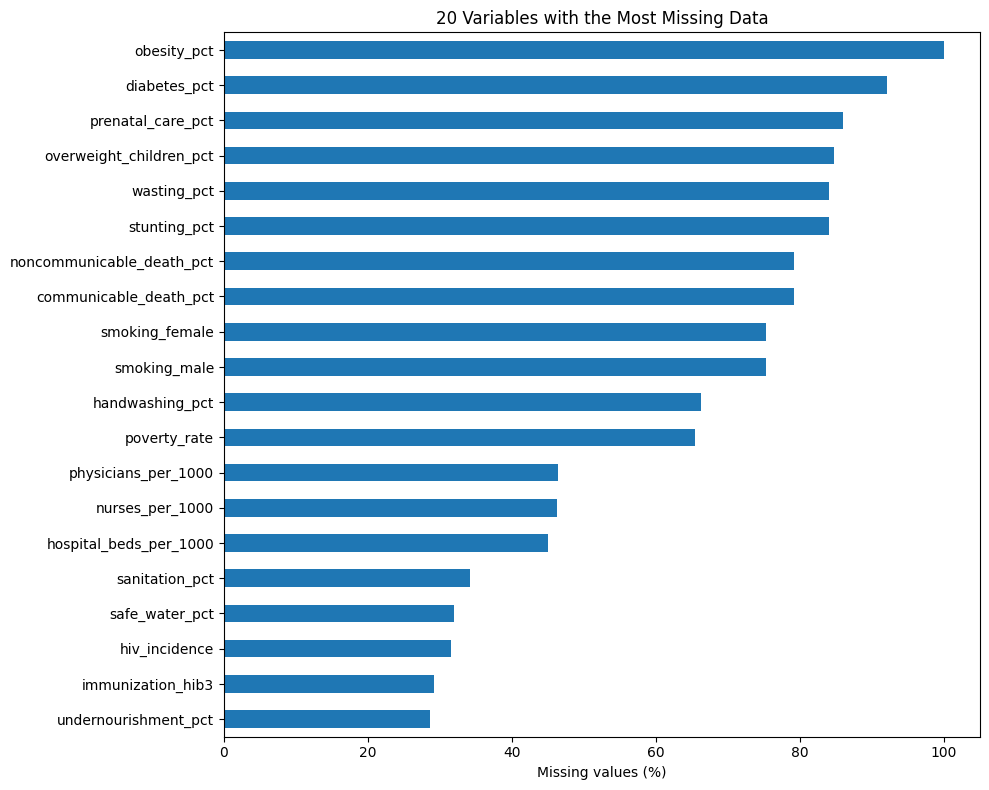

In [ ]:
# STEP 5 — Missing-value analysis

missing = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
      .to_frame("missing_pct")
)

display(missing.round(1))

plt.figure(figsize=(10, 8))
missing.head(20).sort_values("missing_pct")["missing_pct"].plot(kind="barh")
plt.title("20 Variables with the Most Missing Data")
plt.xlabel("Missing values (%)")
plt.tight_layout()
plt.show()

### Why this step?
Several indicators are incomplete across countries and years. We therefore avoid variables with very high missingness and use median imputation inside the modeling pipeline.

,mean,median,std,count
year,,,,
2000,3.203,2.691,1.704,211
2001,3.145,2.576,1.692,211
2002,3.095,2.544,1.674,211
2003,3.055,2.500,1.653,211
2004,3.028,2.496,1.627,211
2005,2.996,2.452,1.609,211
2006,2.975,2.461,1.587,211
2007,2.961,2.421,1.559,211
2008,2.955,2.404,1.526,211


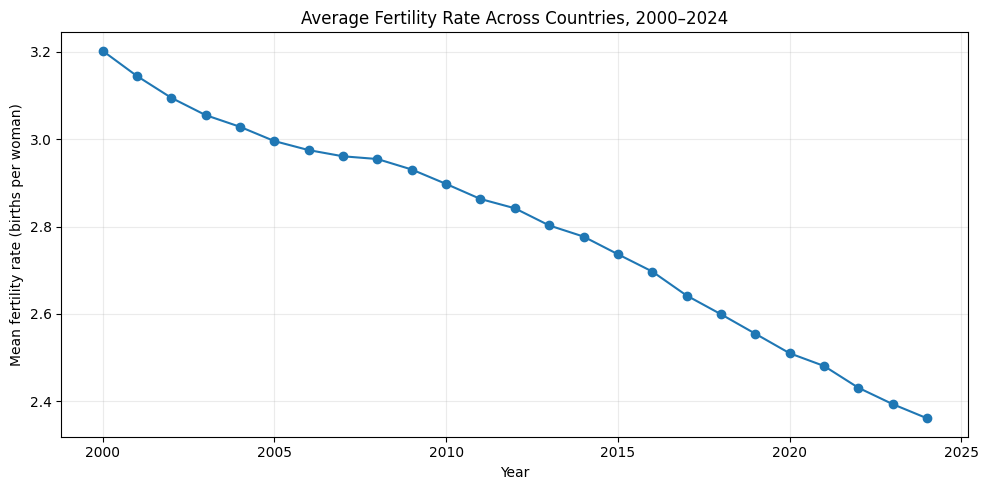

In [ ]:
# STEP 6 — Fertility trend from 2000–2024

yearly_fertility = (
    df.groupby("year")["fertility_rate"]
      .agg(["mean", "median", "std", "count"])
)

display(yearly_fertility.round(3))

plt.figure(figsize=(10, 5))
plt.plot(yearly_fertility.index, yearly_fertility["mean"], marker="o")
plt.title("Average Fertility Rate Across Countries, 2000–2024")
plt.xlabel("Year")
plt.ylabel("Mean fertility rate (births per woman)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Why this step?
This chart directly addresses the time component of the research question by showing how the global average fertility rate changes from 2000 through 2024.

region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,"Middle East, North Africa, Afghanistan & Pakistan",North America,South Asia,Sub-Saharan Africa
year,,,,,,,
2020,2.381,1.699,1.836,2.611,1.501,1.899,4.234
2021,2.344,1.712,1.805,2.560,1.498,1.882,4.170
2022,2.306,1.644,1.791,2.502,1.465,1.870,4.099
2023,2.268,1.601,1.775,2.488,1.429,1.856,4.036
2024,2.242,1.568,1.768,2.465,1.427,1.837,3.969


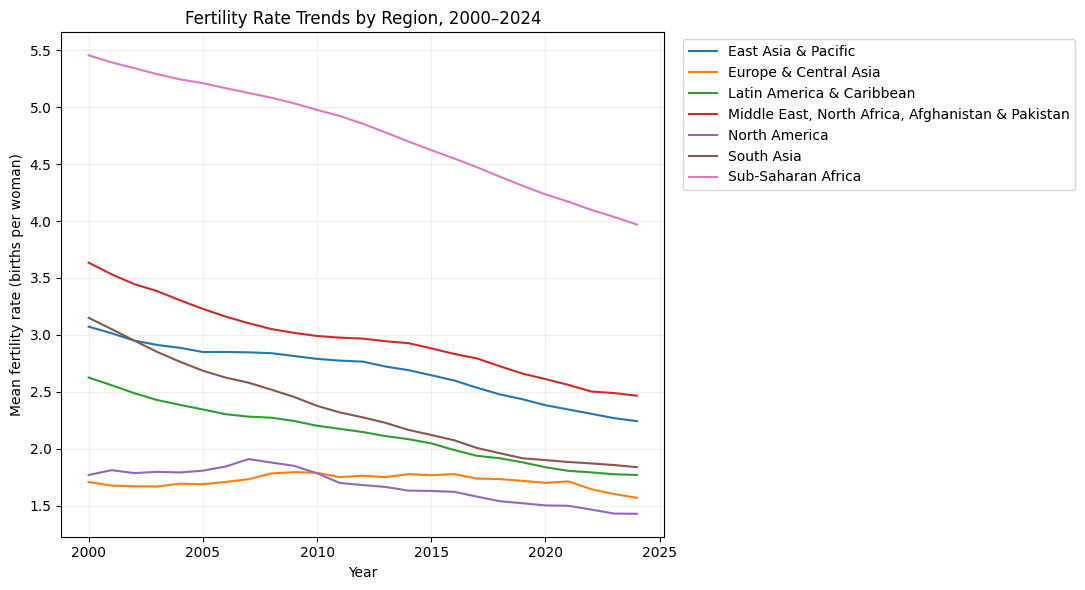

In [ ]:
# STEP 7 — Fertility trends by region

region_year = (
    df.groupby(["year", "region"])["fertility_rate"]
      .mean()
      .unstack()
)

display(region_year.tail().round(3))

plt.figure(figsize=(11, 6))
for region in region_year.columns:
    plt.plot(region_year.index, region_year[region], label=region)

plt.title("Fertility Rate Trends by Region, 2000–2024")
plt.xlabel("Year")
plt.ylabel("Mean fertility rate (births per woman)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Why this step?
The project is specifically about **regional differences**. This visualization shows whether regions follow similar or different fertility trajectories over time.

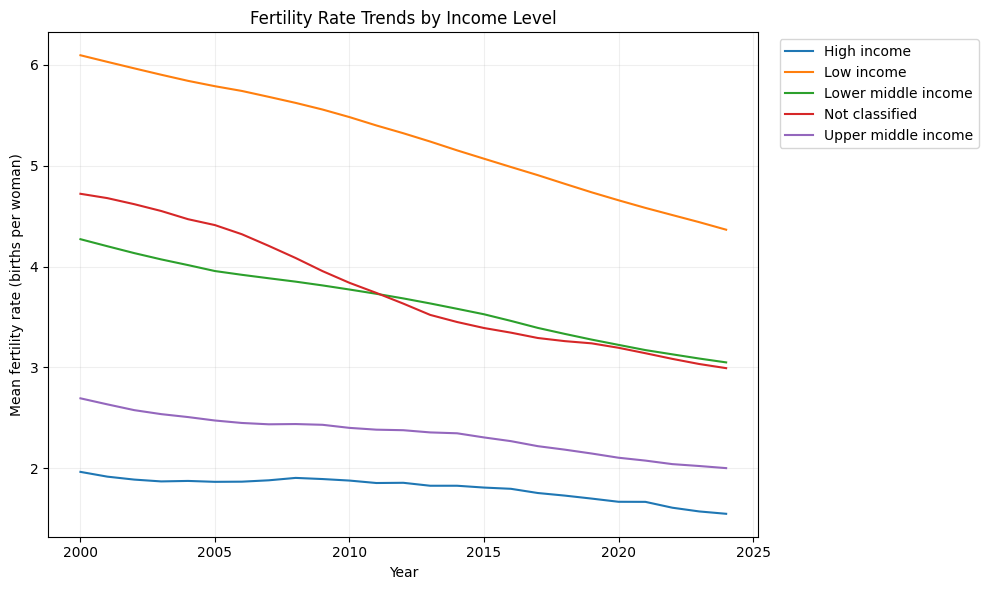

In [ ]:
# STEP 8 — Fertility by income level

income_year = (
    df.groupby(["year", "income_level"])["fertility_rate"]
      .mean()
      .unstack()
)

plt.figure(figsize=(10, 6))
for group in income_year.columns:
    plt.plot(income_year.index, income_year[group], label=group)

plt.title("Fertility Rate Trends by Income Level")
plt.xlabel("Year")
plt.ylabel("Mean fertility rate (births per woman)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Why this step?
Income level provides a broad socioeconomic comparison. It lets us see whether fertility trends differ systematically across development levels.

# Additional EDA — Life Expectancy Trends

To strengthen the health-indicator portion of the project, the next two visualizations examine **average life expectancy by year**:

1. By world region
2. By income level

These plots help us compare how a major health outcome changed alongside fertility patterns from 2000–2024.


region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,"Middle East, North Africa, Afghanistan & Pakistan",North America,South Asia,Sub-Saharan Africa
year,,,,,,,
2020,72.78,77.60,73.84,73.63,79.99,73.10,62.98
2021,72.26,77.24,72.53,73.12,79.84,72.26,62.18
2022,73.03,78.31,74.76,75.12,80.20,74.48,63.08
2023,73.37,78.93,75.38,75.60,80.77,74.75,64.56
2024,73.53,79.15,75.54,75.90,81.16,75.00,64.78


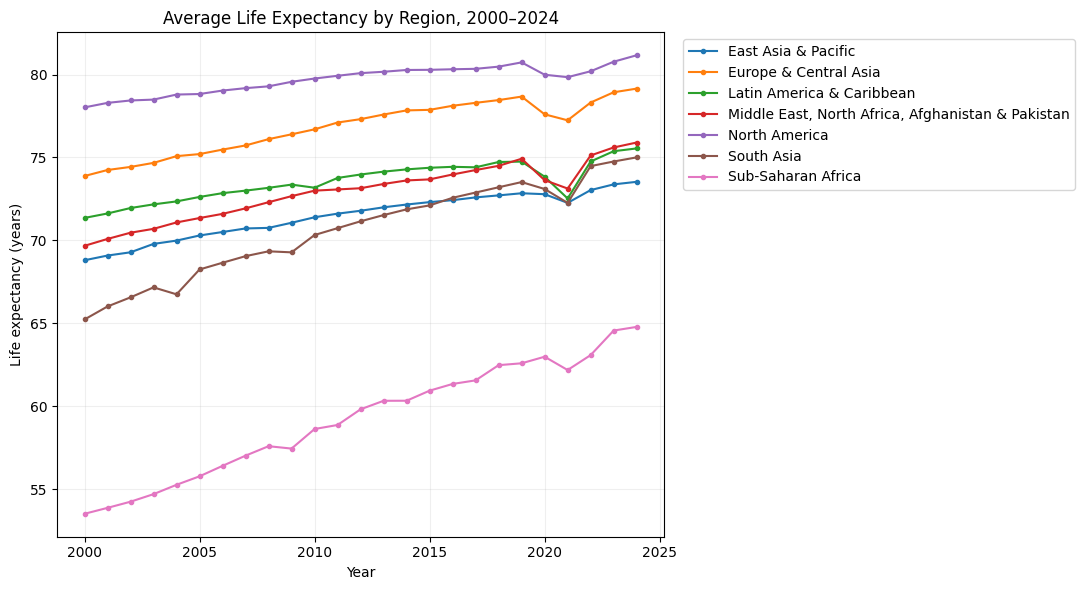

In [ ]:
# LIFE EXPECTANCY BY YEAR AND REGION

life_region_year = (
    df.groupby(["year", "region"])["life_expectancy"]
      .mean()
      .unstack()
)

display(life_region_year.tail().round(2))

plt.figure(figsize=(11, 6))

for region in life_region_year.columns:
    plt.plot(
        life_region_year.index,
        life_region_year[region],
        marker="o",
        markersize=3,
        label=region
    )

plt.title("Average Life Expectancy by Region, 2000–2024")
plt.xlabel("Year")
plt.ylabel("Life expectancy (years)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.20)
plt.tight_layout()
plt.show()


### Interpretation
This plot shows how average life expectancy changed over time within each world region. It can be compared with the regional fertility-rate plot to see whether regions with higher or improving life expectancy also tend to show different fertility patterns.

This is an exploratory association only and should not be interpreted as proof that life expectancy causes fertility to change.


income_level,High income,Low income,Lower middle income,Not classified,Upper middle income
year,,,,,
2020,78.60,62.24,66.93,69.17,72.25
2021,78.11,61.59,66.20,68.43,71.22
2022,78.93,61.77,68.07,69.73,73.37
2023,79.59,64.02,68.54,69.91,73.81
2024,79.79,64.22,68.73,70.14,74.06


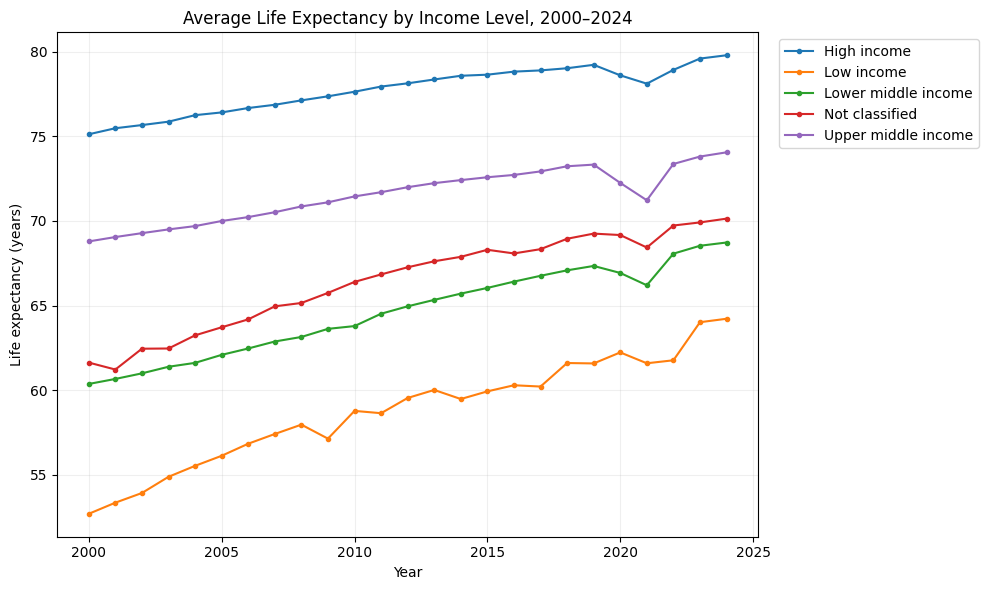

In [ ]:
# LIFE EXPECTANCY BY YEAR AND INCOME LEVEL

life_income_year = (
    df.groupby(["year", "income_level"])["life_expectancy"]
      .mean()
      .unstack()
)

display(life_income_year.tail().round(2))

plt.figure(figsize=(10, 6))

for income_group in life_income_year.columns:
    plt.plot(
        life_income_year.index,
        life_income_year[income_group],
        marker="o",
        markersize=3,
        label=income_group
    )

plt.title("Average Life Expectancy by Income Level, 2000–2024")
plt.xlabel("Year")
plt.ylabel("Life expectancy (years)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.20)
plt.tight_layout()
plt.show()


### Interpretation
This plot compares life-expectancy trends across income groups. It provides another way to examine socioeconomic differences in health outcomes and gives useful context for the fertility-rate trends by income level.

Together, the fertility and life-expectancy plots help show how demographic and health patterns differ across regions and levels of economic development.


In [ ]:
# STEP 9 — Select candidate predictors

# We exclude variables that are too close to the target conceptually.
# This helps avoid an artificially strong model built on direct fertility proxies.
excluded_from_model = {
    "country_code",
    "country_name",
    "fertility_rate",
    "birth_rate",
    "adolescent_fertility",
    "population_growth"
}

categorical_features = ["region", "income_level"]

numeric_candidates = [
    c for c in df.columns
    if c not in excluded_from_model
    and c not in categorical_features
    and pd.api.types.is_numeric_dtype(df[c])
]

# Keep variables with no more than 50% missingness
numeric_features = [
    c for c in numeric_candidates
    if df[c].isna().mean() <= 0.50
]

print("Numeric predictors selected:", len(numeric_features))
for c in numeric_features:
    print(f"- {c}: {df[c].isna().mean()*100:.1f}% missing")

print("\nCategorical predictors:", categorical_features)

Numeric predictors selected: 28
- year: 0.0% missing
- population: 0.0% missing
- urban_pct: 0.0% missing
- life_expectancy: 0.0% missing
- life_expectancy_male: 0.0% missing
- life_expectancy_female: 0.0% missing
- death_rate: 0.0% missing
- health_expenditure_pct_gdp: 14.4% missing
- health_expenditure_per_capita: 14.5% missing
- physicians_per_1000: 46.3% missing
- hospital_beds_per_1000: 45.1% missing
- nurses_per_1000: 46.3% missing
- under5_mortality: 8.1% missing
- neonatal_mortality: 8.1% missing
- maternal_mortality: 12.6% missing
- tb_incidence: 4.1% missing
- hiv_incidence: 31.5% missing
- alcohol_per_capita: 26.6% missing
- safe_water_pct: 31.9% missing
- sanitation_pct: 34.2% missing
- immunization_measles: 9.9% missing
- immunization_dpt: 9.9% missing
- immunization_bcg: 26.4% missing
- immunization_pol3: 9.9% missing
- immunization_hib3: 29.2% missing
- undernourishment_pct: 28.7% missing
- gdp_per_capita: 3.1% missing
- gdp_per_capita_ppp: 8.3% missing

Categorical pred

### Why these predictors?
The research question asks about health and socioeconomic indicators. We therefore include variables such as life expectancy, mortality, health spending, healthcare resources, sanitation, immunization, undernourishment, GDP, urbanization, and year.

We exclude `birth_rate`, `adolescent_fertility`, and `population_growth` from the main model because they are very close to fertility itself and could make prediction performance look stronger without adding much explanatory value.

,correlation_with_fertility
under5_mortality,0.852
life_expectancy_female,-0.847
neonatal_mortality,0.829
life_expectancy,-0.826
maternal_mortality,0.805
safe_water_pct,-0.804
life_expectancy_male,-0.793
physicians_per_1000,-0.669
undernourishment_pct,0.668
sanitation_pct,-0.660


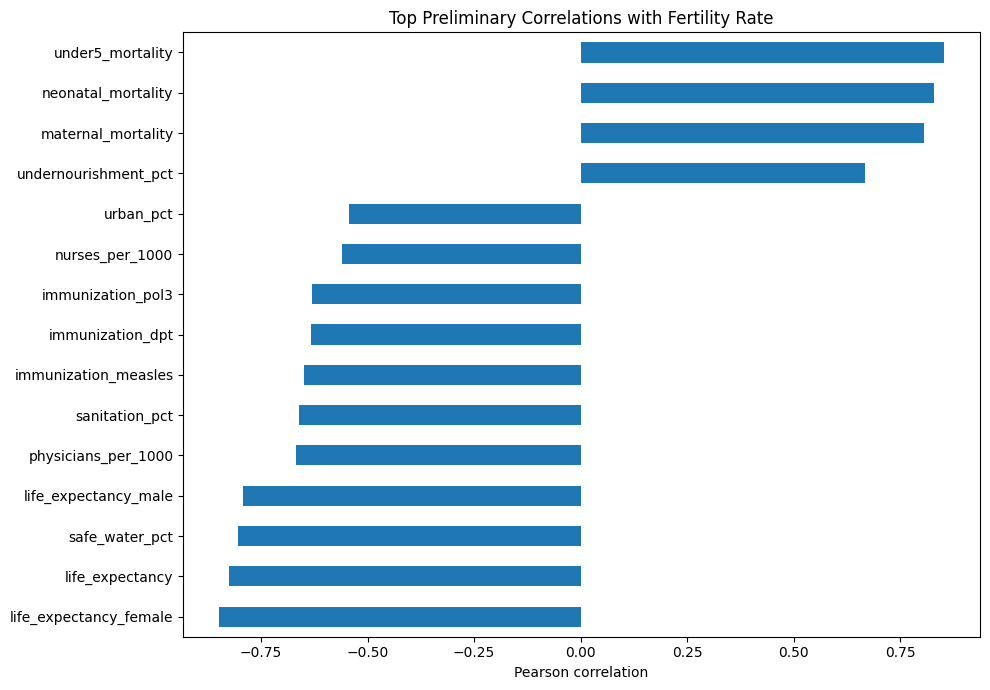

In [ ]:
# STEP 10 — Correlation analysis

corr_cols = ["fertility_rate"] + numeric_features

correlations = (
    df[corr_cols]
      .corr(numeric_only=True)["fertility_rate"]
      .drop("fertility_rate")
      .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(correlations.to_frame("correlation_with_fertility").round(3))

plt.figure(figsize=(10, 7))
correlations.head(15).sort_values().plot(kind="barh")
plt.title("Top Preliminary Correlations with Fertility Rate")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

### Interpretation
Correlation helps identify variables that move together with fertility, but it does **not** establish causation. Strongly correlated predictors can also overlap in the information they contain.

In [ ]:
# STEP 11 — Create modeling data

target = "fertility_rate"

X = df[numeric_features + categorical_features].copy()
y = df[target].copy()

print("Modeling rows:", len(X))
print("Total predictors before encoding:", X.shape[1])

Modeling rows: 5275
Total predictors before encoding: 30


### Why this step?
The target is separated from the predictors so the model does not accidentally use fertility information as an input.

In [ ]:
# STEP 12 — Time-based train/test split

# Train on earlier years, test on later years.
train_mask = df["year"] <= 2019
test_mask = df["year"] >= 2020

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

print("Training period:", df.loc[train_mask, "year"].min(), "-", df.loc[train_mask, "year"].max())
print("Testing period:", df.loc[test_mask, "year"].min(), "-", df.loc[test_mask, "year"].max())
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training period: 2000 - 2019
Testing period: 2020 - 2024
Training rows: 4220
Testing rows: 1055


### Why a time-based split?
Because the same countries appear repeatedly over time, a random split can allow information from later years to leak into model evaluation. Training on 2000–2019 and testing on 2020–2024 is a stronger test of whether the model generalizes to future years.

In [ ]:
# STEP 13 — Preprocessing

numeric_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_scaled = ColumnTransformer([
    ("num", numeric_scaled, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

preprocessor_tree = ColumnTransformer([
    ("num", numeric_unscaled, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

print("Preprocessing pipelines created.")

Preprocessing pipelines created.


### Why this preprocessing?
- Missing numeric values are replaced using the median.
- Region and income level are converted to numeric one-hot indicators.
- Linear and Ridge Regression receive standardized numeric variables.
- Tree models do not require numeric scaling.

In [ ]:
# STEP 14 — Define baseline and comparison models

models = {
    "Mean Baseline": Pipeline([
        ("preprocess", preprocessor_tree),
        ("model", DummyRegressor(strategy="mean"))
    ]),

    "Linear Regression": Pipeline([
        ("preprocess", preprocessor_scaled),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("preprocess", preprocessor_scaled),
        ("model", Ridge(alpha=10.0))
    ]),

    "Random Forest": Pipeline([
        ("preprocess", preprocessor_tree),
        ("model", RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocess", preprocessor_tree),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.03,
            max_depth=2,
            random_state=RANDOM_STATE
        ))
    ])
}

for name in models:
    print("-", name)

- Mean Baseline
- Linear Regression
- Ridge Regression
- Random Forest
- Gradient Boosting


## Slide 10 — Baseline

The **Mean Baseline** predicts the average training-set fertility rate for every test observation. This gives us the minimum benchmark that more advanced models should outperform.

We then compare:
- Linear Regression — interpretable statistical baseline
- Ridge Regression — linear model with regularization
- Random Forest — nonlinear ensemble model
- Gradient Boosting — sequential nonlinear model

In [ ]:
# STEP 15 — Time-based holdout results

test_results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred

    test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

test_results_df = (
    pd.DataFrame(test_results)
      .sort_values("RMSE")
      .reset_index(drop=True)
)

print("PRELIMINARY TIME-BASED TEST RESULTS")
display(test_results_df.round(3))

## Slide 11 — Evaluation and Definition of Success

Because fertility rate is continuous, we use:

- **MAE:** average absolute prediction error in births per woman
- **RMSE:** penalizes larger prediction errors more strongly
- **R²:** percentage of variation in fertility explained by the model

### Success criterion
A useful model should:
1. Clearly outperform the Mean Baseline on MAE and RMSE
2. Achieve a positive and substantially higher R²
3. Remain reasonably stable when countries are held out during GroupKFold validation

In [ ]:
# STEP 16 — Model comparison plot

plot_df = test_results_df.set_index("Model")[["MAE", "RMSE"]]

plot_df.plot(kind="bar", figsize=(9, 5))
plt.title("Preliminary Model Comparison — 2020–2024 Holdout")
plt.ylabel("Error (births per woman)")
plt.xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Slide 12 — Preliminary Results

These results are preliminary. The model is trained on 2000–2019 and tested on 2020–2024 so that evaluation reflects future-year prediction rather than a random split.

In [ ]:
# STEP 17 — 5-fold GroupKFold validation by country

groups = df["country_code"]
group_cv = GroupKFold(n_splits=5)

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=group_cv,
        groups=groups,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        }
    )

    cv_results.append({
        "Model": name,
        "GroupCV_MAE": -scores["test_mae"].mean(),
        "GroupCV_RMSE": -scores["test_rmse"].mean(),
        "GroupCV_R2": scores["test_r2"].mean()
    })

cv_results_df = (
    pd.DataFrame(cv_results)
      .sort_values("GroupCV_RMSE")
      .reset_index(drop=True)
)

print("5-FOLD GROUPKFold RESULTS — ENTIRE COUNTRIES HELD OUT")
display(cv_results_df.round(3))

5-FOLD GROUPKFold RESULTS — ENTIRE COUNTRIES HELD OUT


,Model,GroupCV_MAE,GroupCV_RMSE,GroupCV_R2
0,Random Forest,0.399,0.536,0.859
1,Ridge Regression,0.447,0.596,0.830
2,Linear Regression,0.450,0.605,0.825
3,Gradient Boosting,0.478,0.624,0.811
4,Mean Baseline,1.194,1.468,-0.015


### Why GroupKFold?
A country has 25 yearly observations. GroupKFold keeps all years from a country together, so the model is tested on countries it did not see during training. This checks geographic generalization and reduces leakage from repeated country observations.

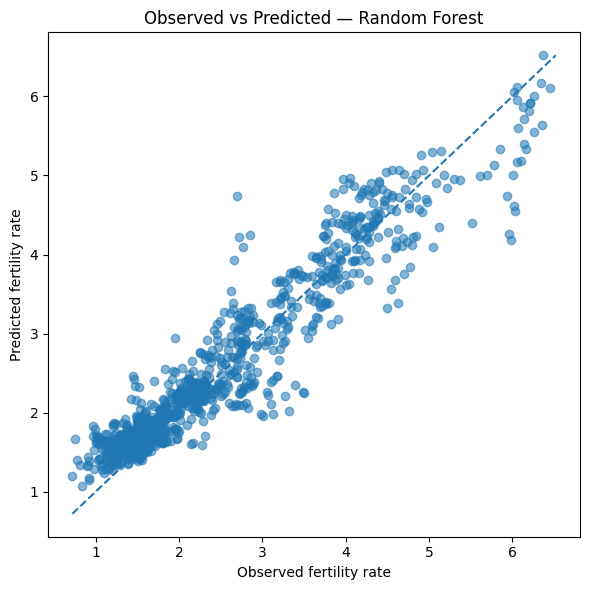

Best preliminary model: Random Forest


In [ ]:
# STEP 18 — Observed vs predicted for the best non-baseline model

non_baseline = test_results_df[test_results_df["Model"] != "Mean Baseline"]
best_model_name = non_baseline.iloc[0]["Model"]

best_model = models[best_model_name]
best_model.fit(X_train, y_train)
best_pred = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.55)

low = min(y_test.min(), best_pred.min())
high = max(y_test.max(), best_pred.max())

plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Observed fertility rate")
plt.ylabel("Predicted fertility rate")
plt.title(f"Observed vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

print("Best preliminary model:", best_model_name)

,feature,importance
0,num__life_expectancy_female,0.6433
1,num__under5_mortality,0.1368
2,num__death_rate,0.0332
3,num__maternal_mortality,0.0200
4,num__alcohol_per_capita,0.0186
5,cat__income_level_Low income,0.0149
6,num__urban_pct,0.0146
7,cat__region_Sub-Saharan Africa,0.0145
8,num__tb_incidence,0.0119
9,num__hiv_incidence,0.0105


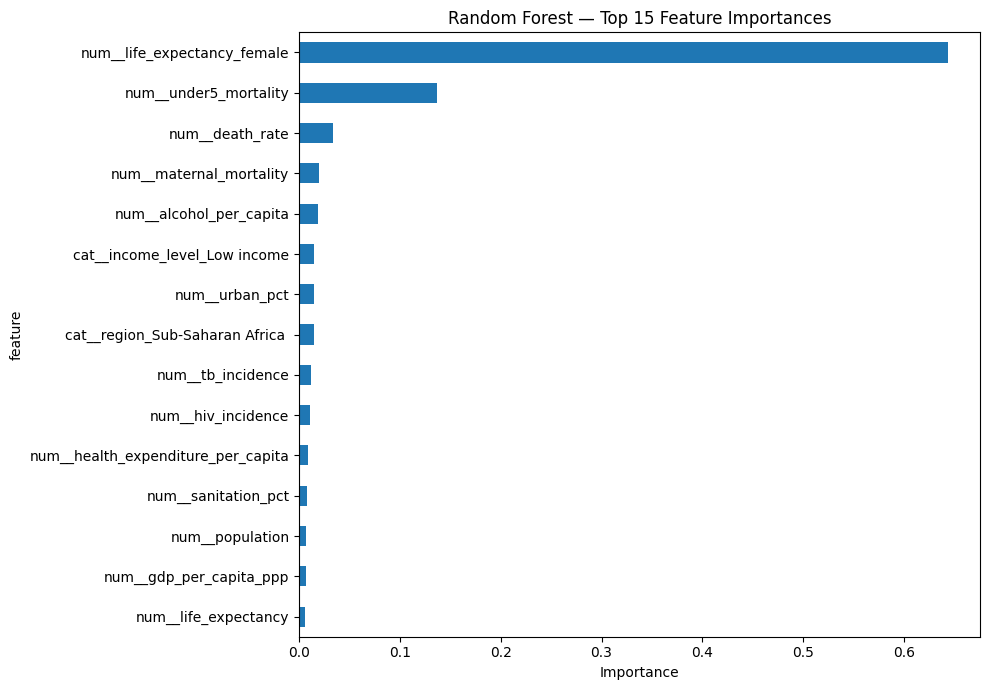

In [ ]:
# STEP 19 — Random Forest feature importance

rf = models["Random Forest"]
rf.fit(X_train, y_train)

feature_names = rf.named_steps["preprocess"].get_feature_names_out()
importances = rf.named_steps["model"].feature_importances_

importance_df = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(importance_df.head(20).round(4))

plt.figure(figsize=(10, 7))
(
    importance_df.head(15)
    .sort_values("importance")
    .set_index("feature")["importance"]
    .plot(kind="barh")
)
plt.title("Random Forest — Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### Interpretation
Feature importance shows which inputs the Random Forest relied on most. It is useful for interpretation, but it should not be described as proof that a variable causes fertility to change.

,observations,observed_mean,predicted_mean,MAE
region,,,,
Sub-Saharan Africa,240,4.102,4.128,0.396
East Asia & Pacific,175,2.308,2.423,0.280
"Middle East, North Africa, Afghanistan & Pakistan",105,2.525,2.468,0.270
South Asia,30,1.869,2.073,0.266
Latin America & Caribbean,210,1.795,1.962,0.232
Europe & Central Asia,280,1.645,1.730,0.215
North America,15,1.464,1.592,0.128


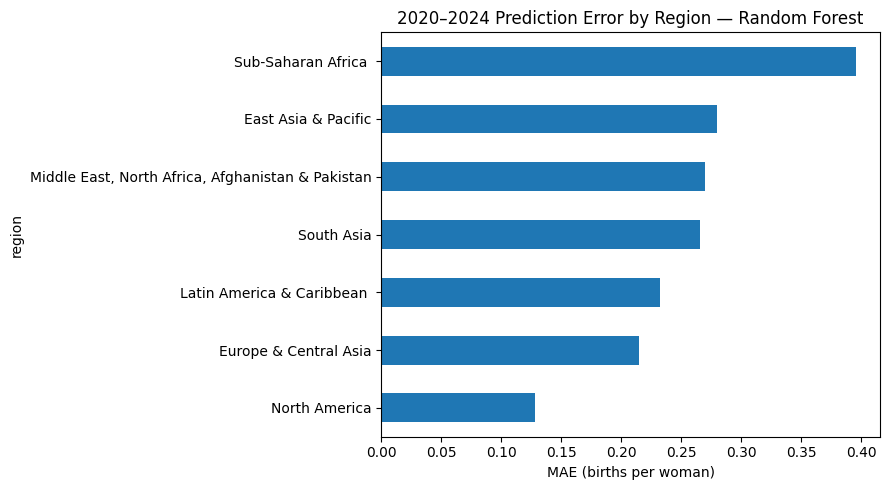

In [ ]:
# STEP 20 — Regional error analysis on the 2020–2024 holdout

test_meta = df.loc[test_mask, ["country_name", "region", "year", "fertility_rate"]].copy()
test_meta["predicted_fertility"] = best_pred
test_meta["absolute_error"] = (
    test_meta["fertility_rate"] - test_meta["predicted_fertility"]
).abs()

regional_error = (
    test_meta.groupby("region")
    .agg(
        observations=("fertility_rate", "count"),
        observed_mean=("fertility_rate", "mean"),
        predicted_mean=("predicted_fertility", "mean"),
        MAE=("absolute_error", "mean")
    )
    .sort_values("MAE", ascending=False)
)

display(regional_error.round(3))

plt.figure(figsize=(9, 5))
regional_error["MAE"].sort_values().plot(kind="barh")
plt.title(f"2020–2024 Prediction Error by Region — {best_model_name}")
plt.xlabel("MAE (births per woman)")
plt.tight_layout()
plt.show()

### Why this matters
The overall model score can hide regional weaknesses. This analysis checks whether prediction errors are larger in some world regions than others.

In [ ]:
# STEP 21 — Largest prediction errors

largest_errors = (
    test_meta
    .sort_values("absolute_error", ascending=False)
    .head(20)
)

display(largest_errors.round(3))

,country_name,region,year,fertility_rate,predicted_fertility,absolute_error
2773,Lesotho,Sub-Saharan Africa,2023,2.694,4.744,2.050
974,"Congo, Dem. Rep.",Sub-Saharan Africa,2024,5.981,4.183,1.798
799,Central African Republic,Sub-Saharan Africa,2024,5.954,4.263,1.691
2772,Lesotho,Sub-Saharan Africa,2022,2.716,4.221,1.505
4574,Chad,Sub-Saharan Africa,2024,6.028,4.550,1.478
4249,"Somalia, Fed. Rep.",Sub-Saharan Africa,2024,6.013,4.609,1.404
2770,Lesotho,Sub-Saharan Africa,2020,2.846,4.248,1.402
2771,Lesotho,Sub-Saharan Africa,2021,2.769,4.097,1.328
2396,Kazakhstan,Europe & Central Asia,2021,3.320,2.026,1.294
2774,Lesotho,Sub-Saharan Africa,2024,2.664,3.934,1.270


### Error-analysis interpretation
Large errors may indicate countries where fertility is influenced by variables not captured well in this dataset, such as education, reproductive-health access, marriage patterns, cultural factors, family policy, migration, or conflict.

In [ ]:
# STEP 22 — Compare model with and without region/income context

numeric_only_preprocessor = ColumnTransformer([
    ("num", numeric_unscaled, numeric_features)
])

rf_numeric_only = Pipeline([
    ("preprocess", numeric_only_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

context_rows = []

for label, model, X_use in [
    ("Numeric health/socioeconomic indicators only",
     rf_numeric_only,
     df[numeric_features]),

    ("Numeric indicators + region + income",
     models["Random Forest"],
     X)
]:
    model.fit(X_use.loc[train_mask], y_train)
    pred = model.predict(X_use.loc[test_mask])

    context_rows.append({
        "Specification": label,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

context_comparison_df = pd.DataFrame(context_rows)
display(context_comparison_df.round(3))

,Specification,MAE,RMSE,R2
0,Numeric health/socioeconomic indicators only,0.283,0.389,0.898
1,Numeric indicators + region + income,0.276,0.376,0.905


### Objective-to-method connection
This comparison directly tests whether adding **regional and income context** improves prediction beyond the health and socioeconomic indicators alone.

In [ ]:
# STEP 23 — Export presentation-ready tables

test_results_df.to_csv("time_holdout_model_results.csv", index=False)
cv_results_df.to_csv("country_group_cv_results.csv", index=False)
yearly_fertility.to_csv("fertility_trend_2000_2024.csv")
region_year.to_csv("fertility_by_region_2000_2024.csv")
importance_df.to_csv("random_forest_feature_importance.csv", index=False)
regional_error.to_csv("regional_error_2020_2024.csv")
context_comparison_df.to_csv("regional_context_model_comparison.csv", index=False)

print("Saved presentation-ready tables:")
print("- time_holdout_model_results.csv")
print("- country_group_cv_results.csv")
print("- fertility_trend_2000_2024.csv")
print("- fertility_by_region_2000_2024.csv")
print("- random_forest_feature_importance.csv")
print("- regional_error_2020_2024.csv")
print("- regional_context_model_comparison.csv")

Saved presentation-ready tables:
- time_holdout_model_results.csv
- country_group_cv_results.csv
- fertility_trend_2000_2024.csv
- fertility_by_region_2000_2024.csv
- random_forest_feature_importance.csv
- regional_error_2020_2024.csv
- regional_context_model_comparison.csv


,Observations
region,
Europe & Central Asia,1400
Sub-Saharan Africa,1200
Latin America & Caribbean,1050
East Asia & Pacific,875
"Middle East, North Africa, Afghanistan & Pakistan",525
South Asia,150
North America,75


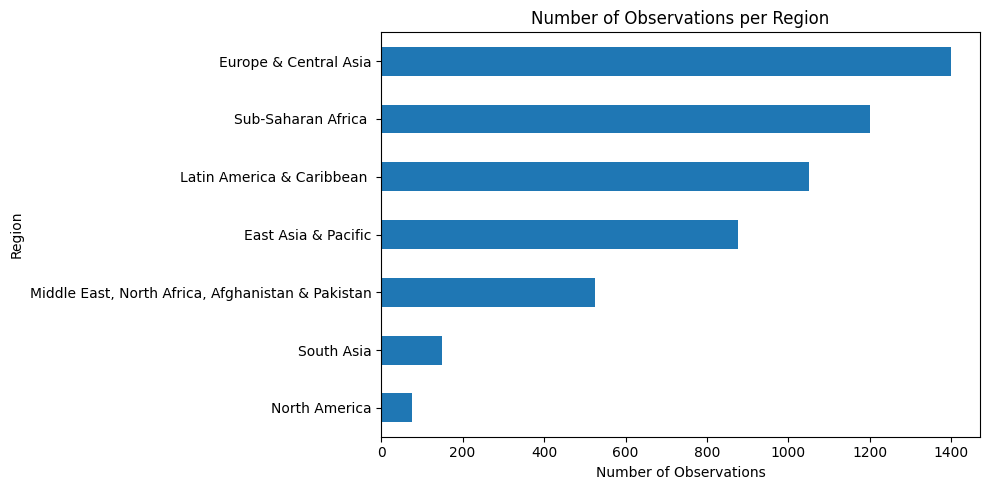

In [ ]:

region_counts = df["region"].value_counts()

display(region_counts.to_frame("Observations"))

plt.figure(figsize=(10, 5))
region_counts.sort_values().plot(kind="barh")

plt.title("Number of Observations per Region")
plt.xlabel("Number of Observations")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

# Main Findings to Use in the Presentation

### Dataset
- 5,275 country-year observations
- 211 countries
- 25 years: 2000–2024
- 48 columns
- Target: `fertility_rate`

### Modeling logic
- Mean prediction is the simplest baseline.
- Linear Regression provides an interpretable benchmark.
- Ridge Regression reduces instability from correlated predictors.
- Random Forest and Gradient Boosting capture nonlinear relationships.
- Time-based testing evaluates future years.
- GroupKFold tests generalization to unseen countries.

### Important limitations
- Missingness is high for some indicators.
- The dataset contains country-level averages, so within-country variation is hidden.
- Correlation and feature importance do not prove causation.
- Important fertility-related social variables may be missing.
- Model performance can vary across regions.

### Capstone II direction
- Tune model hyperparameters.
- Add stronger socioeconomic variables if available.
- Explore lagged predictors and changes over time.
- Consider panel-data/statistical approaches.
- Build an interactive regional fertility dashboard.
- Perform deeper interpretability and error analysis.